# Auswertung verusch 243

## Aufgabe 1: Import und graphische Darstellung der Messdaten

Hier werden die Messdaten des Multimeters aufgetragen und Betrachtet


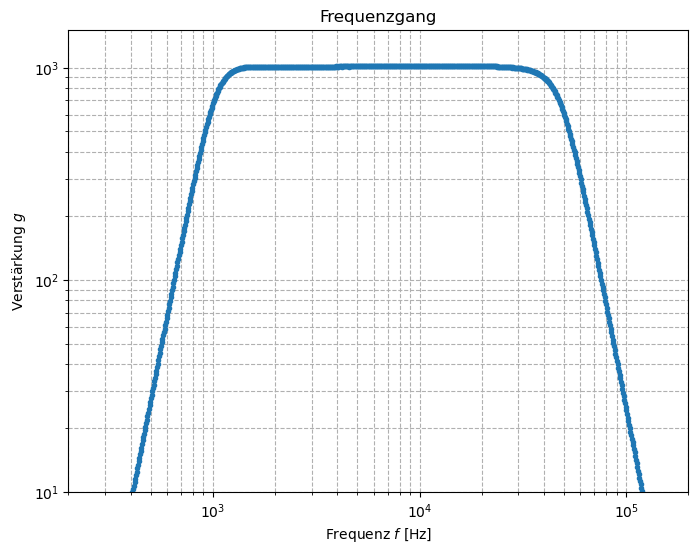

In [40]:
import matplotlib.pyplot as plt

import numpy as np

import numpy as np
# Schöner für import
np.seterr(over='ignore', invalid='ignore')




f, gain_roh = np.loadtxt('Messung Gruppe2.csv', skiprows=1, delimiter=',', unpack=True, usecols=(0, 1))

D = 1e-3 # Verstärkung


g = gain_roh / D


fig, ax = plt.subplots(figsize=(8, 6))

# Loglog plot
ax.set_xlabel('Frequenz $f$ [Hz]')
ax.set_ylabel('Verstärkung $g$')
ax.set_title('Frequenzgang')
ax.loglog(f, g, linestyle='None', marker='.', label='Messwerte')
ax.axis([200, 2e5, 10, 1.5E3])
ax.grid(True, which='both', ls='--')




#### Kommentar

Hier Lässt sich der erwartete Frequenzgang des Bandpassfilters anhand der symmetrischen Flanken sehr deutlich erkennen. (Der Abgleich stimmt mit dem gezeigten Plot der Software überein). Es lässt sich ihm hochfrequenten Bereich kurz vor Beginnn der Flanke bereits ganz leicht der Frequenzgang des Aufbaus ohne Bandpassfilters erkennen.

## Aufgabe 2: Funktion anpassen

Nun wird die Bandpassfunktion an die Messdaten gefittet

Fit Parameter: 
V=1012.122+/-0.221, 
W1=46614.034+/-21.372, 
W2=6196.180+/-20.283, 
n1=4.627+/-0.010, 
n2=9.801+/-0.016


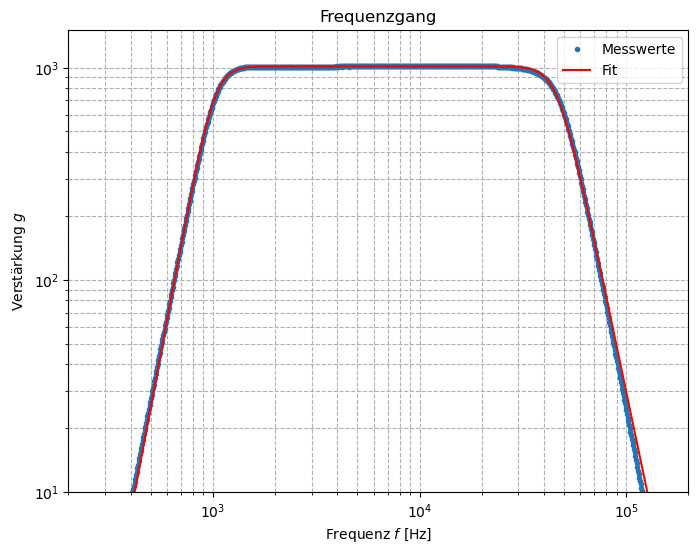

In [41]:
from scipy.optimize import curve_fit

# fitting function (Frequenzgang Bandpass)

def fit_func(*args):
    f, V, W1, W2, n1, n2 = args
    return V/np.sqrt((1 + (f/W1)**(2*n1) * (1 + (W2/f)**(2*n2))))

p0 = [1e3, 1e3, 50000, 5, 5] 
# Verstärkung, untere Grenzfrequenz, obere Grenzfrequenz, Filterordnung unten, Filterordnung oben

popt, pcov = curve_fit(fit_func, f, g, p0)

print(f'Fit Parameter: \nV={popt[0]:.3f}+/-{np.sqrt(pcov[0, 0]):.3f}, \nW1={popt[1]:.3f}+/-{np.sqrt(pcov[1, 1]):.3f}, \nW2={popt[2]:.3f}+/-{np.sqrt(pcov[2, 2]):.3f}, \nn1={popt[3]:.3f}+/-{np.sqrt(pcov[3, 3]):.3f}, \nn2={popt[4]:.3f}+/-{np.sqrt(pcov[4, 4]):.3f}')


if ax.get_legend():
    ax.get_legend().remove()
    
#muss man machen dass sich nicht die fits ansammeln


ax.plot(f, fit_func(f, *popt), 'r-', label='Fit')
ax.legend()

fig
# jens wagner nicht super effizienter Python Programmierer



#### Kommentar

Die Bandpassfunktion 

$$ g(f) = \frac{V}{\sqrt{(1+1/(f/\omega_1)^{2n_1})*(1+(f/\omega_2)^{2n_2})}}$$

wurde mithilfe von Scipy optimize mit diesen Parametern gefittet

V=1012.122+/-0.221, 
W1=46614.034+/-21.372, 
W2=6196.180+/-20.283, 
n1=4.627+/-0.010, 
n2=9.801+/-0.016

Die Unsicherheiten haben sich aus der Kovarianzmatrix ergeben.

Es ist zu erknnen dass die Bandpassfunktion den Erwartungen von Raphael und Jens Wagner entspricht, da die angesetzen p0 Werte nicht stark von den optimalen Fit-Paramtern abweichen.


Auch hier ist wieder zu erkennen, wie der Frequenzgang ohne Bandpassfilter einen minimalen Einfluss zeigt. Der optimale Fit weicht etwas von den Realwerten der Messung ab, da bei hohen Frequenzen die Verstärkung einen stärkeren Abfall gegenüber der Erwartung zeigt. Man kann vermuten, dass bei diesen Frequezen das Messgerät bereits die reale Verstärkung nicht mehr gang genau messen kannn.



## Aufgabe 3 Nummerische Integration

Hier wird das Integral des Frequenzgangs bestimmt, um die Rauschbandbreite $B$ zu bestimmen.

In [42]:
import scipy.integrate as integrate

def_fit_func_squared = lambda *args: fit_func(*args)**2 # hat das Aura?

B=integrate.quad(def_fit_func_squared, f[0], f[-1], args=tuple(popt))

# f[len(f)] (was auch nicht geht weil Arrays ab 0 zählen: es müsste f[len(f)-1] sein) ist nicht so cool wie f[-1]

print(f'Das Integral betraegt: {B[0]:.4e} +/- {B[1]:.4f}')

Das Integral betraegt: 4.7620e+10 +/- 68.1574


#### Kommentar

Das Integral des Frequenzgangs g(f) wurde mithilfe von Scipy.integrate bestimmt. Die Rauschbandbreite $B$ beträgt $$B=4.762 x 10^{10} \,\text{Hz}$$

Die Unsicherheit des Integrals mit $\Delta B \approx 70 \, Hz$ ist um Faktor 9 kleiner und somit vernachlässigbar klein.



## Aufgabe 4 Bestimmung der Boltzmannkonstante

Die Boltzmannkonstante wird nun mithilfe der in der Einleitung bennanten Gleichung $$k_B = \frac{\langle U_{\text{aus}}^2 \rangle - \langle U_V^2 \rangle}{4 T R B} = \frac{m}{4 T B}$$ besitmmt.

m beschreibt dabei die Steigung
$$ m= 4kTB $$
welche aus einem linearen Fit mit $f(0) = 0$ gewonnen wird

### Fitten der Gerade an an die Rauschspannungen
Werte kommen aus dem Messprotokoll (Tabelle 3.2)

Der Statistische Fehler muss zusätzlich noch mit dem Fehler des Voltmeters von 0.3\% quadraisch addiert werden:

$$\Delta U_{aus} = \sqrt{(U_{aus}*0.003)^2 + \Delta U^2}$$
Die Formel für die Differenz lautet:
$$D = U_{aus}^2 - U_V^2  $$

Die zugehörige Fehlerformel ist:

$$\Delta D = \sqrt{(2U_{\text{aus}}\Delta U_{\text{aus}})^2 + (2U_V\Delta U_V)^2}$$




Fit Parameter: 
m=786.557e-12 +/- 2.189e-12


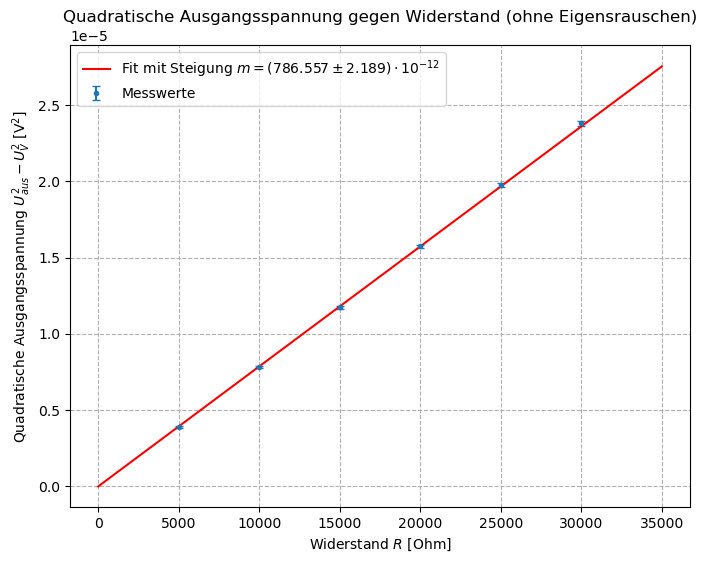

In [51]:
R = np.array([5, 10, 15, 20, 25, 30])*1e3 
U_aus = np.array([2.4039, 3.1146, 3.6898, 4.1987, 4.6533, 5.0669])*1e-3 #millivolt
fehler_U_stat = np.array([0.00088, 0.00124, 0.00148, 0.00167, 0.00181, 0.00178])*1e-3 #millivolt
fehler_U_aus = np.sqrt((fehler_U_stat*1e-3)**2 + (U_aus*0.003)**2) #millivolt

U_V = 1.3718*1e-3 #Eigensrauschen
fehler_U_V = np.sqrt((0.00048*1e-2)**2 + (U_V*0.003)**2)*1e-3 #Eigensrauschen

diff = U_aus**2 - U_V**2
fehler_diff = np.sqrt((2*U_aus*fehler_U_aus)**2 + (2*U_V*fehler_U_V)**2)

fig2, ax2 = plt.subplots(figsize=(8, 6))

ax2.errorbar(R, diff, yerr=fehler_diff, fmt='.', label='Messwerte', capsize=3)


linear = lambda x, m : m*x+0

popt2, pcov2 = curve_fit(linear, R, diff, sigma=fehler_diff)
# Berechne die skalierten Werte für den e-12 Exponenten
m_scaled = popt2[0] / 1e-12
m_err_scaled = np.sqrt(pcov2[0, 0]) / 1e-12

# 1. Print-Ausgabe anpassen
print(f'Fit Parameter: \nm={m_scaled:.3f}e-12 +/- {m_err_scaled:.3f}e-12')

# 2. Plot-Beschriftung anpassen (mit sauberem KaTeX-kompatiblem Text für VS Code)
x = np.linspace(0, 35e3, 100)
ax2.plot(x, linear(x, *popt2), 'r-', 
         label=rf'Fit mit Steigung $m=({m_scaled:.3f} \pm {m_err_scaled:.3f}) \cdot 10^{{-12}}$')

ax2.set_xlabel('Widerstand $R$ [Ohm]')
ax2.set_ylabel('Quadratische Ausgangsspannung $U_{aus}^2 - U_V^2$ [V$^2$]')
ax2.set_title('Quadratische Ausgangsspannung gegen Widerstand (ohne Eigensrauschen)')
ax2.grid(True, which='both', ls='--')
ax2.legend()

#### Kommentar
Die gefittete Gerade besitzt die Steigung $m = (786.6\,\pm 2.2) \cdot 10^{-12} \,\frac{\text{V}^2}{\Omega}$.

Dass sie durch den Ursprung verläuft ist beim Fit festgelegt worden

### Dikussion der Güte der Fits:
Die Güte der Fits kann anhand des Chi-Quadrat-Tests getestet werden. Der Chi-Quadrat-Wert wird berechnet, indem die Summe der quadrierten Differenzen zwischen den beobachteten Werten und den durch das Modell vorhergesagten Werten, gewichtet durch die Varianz der Beobachtungen, genommen wird. Ein niedriger Chi-Quadrat-Wert im Vergleich zu den Freiheitsgraden deutet auf eine gute Anpassung hin, während ein hoher Wert auf eine schlechte Anpassung hinweist.

In [53]:
from scipy.stats import chi2

chisquare = np.sum(((linear(R, *popt2) - diff)**2/ fehler_diff**2))
dof = 5 
chi2_reduced = chisquare / dof
print(f'Chi-Quadrat: {chisquare:.3f}, Freiheitsgrade: {dof}, Reduziertes Chi-Quadrat: {chi2_reduced:.3f}')

prob = round(1 - chi2.cdf(chisquare, dof), 2)*100

print(f'Fitwahrscheinlichkeit = {prob:.2f}%')

Chi-Quadrat: 4.667, Freiheitsgrade: 5, Reduziertes Chi-Quadrat: 0.933
Fitwahrscheinlichkeit = 46.00%


#### Kommentar

Der berechnete reduzierte Chi-Quadrat-Wert beträgt $\chi^2_{\text{red}} = 0.933$ und liegt damit sehr nah am Optimalwert von 1. Es lässt sich darauf schlussfolgern (mit 46\% Wahrscheinlichkeit), dass die Abweichungen tatsächlich von statistischer Natur sind, und nur ein sehr kleiner systematischer Fehler vorliegt.

### Bestimmung der Boltzmannkonstante

Nun wird mithilfe der Steigung des Fits die Boltzmannkonstante bestimmt.

Nach Anleitung wird ein systematischer Fehle für B von 2\% angenommen.

Die Raumtemperatur beträgt $T = (22.30\,\pm 0.10)^\circ\text{C}$


In [54]:
import uncertainties as unc

m = unc.ufloat(popt2[0], np.sqrt(pcov2[0, 0]))
T = unc.ufloat(22.3+273.15, 0.1) # Raumtemperatur in Kelvin
B_ufloat = unc.ufloat(B[0], B[1]) # Bandbreite mit Unsicherheit statistisch

k = m / (4 * T * B_ufloat)

print(f'Boltzmannkonstante: k_B = {k:.3uP} J/K')

print(f'systematischer Fehler: {k.nominal_value * 0.02:.3e} J/K')


Boltzmannkonstante: k_B = (1.39765±0.00392)×10⁻²³ J/K
systematischer Fehler: 2.795e-25 J/K


In [57]:
from scipy.constants import Boltzmann

sigma_dev = (k.nominal_value - Boltzmann)/np.sqrt(k.std_dev**2 + (k.nominal_value * 0.02)**2)
sigma_dev

np.float64(0.6022138763082926)

## Ergebnis

Die berechnete Boltzmannkonstante beträgt $$ k_B = (1.398\,\pm0.004\,\text{stat.}\,\pm 0.028\,\text{syst.}) \cdot 10^{-23} \frac{\text{J}}{\text{K}}$$

Die Sigma-Abweichung berechnet sich durch
$$ \sigma = \frac{k_B - k_{B,\text{lit}}}{\sqrt{(\Delta \text{stat})^2 + (\Delta \text{syst.})^2}} = 0.6 \Rightarrow 0.6\sigma $$

Dies spricht für eine sehr gute Übereinstimmung

Die getrennte Angabe von statistischem und systematischem Fehler ist sinnvoll, da beide unterschiedliche Ursachen haben: Der statistische Fehler resultiert aus den zufälligen Schwankungen des thermischen Rauschens sowie der Einzelmessungen an den verschiedenen Widerständen und lässt sich durch eine größere Anzahl an Messungen reduzieren. Der systematische Fehler dominiert durch die 2\% Unsicherheit der Rauschbandbreite. $\Delta B$ bleibt für egal wieviele Messungen gleich. Damit verschiebt wird Gesamtergebnis in eine feste Richtung verschoben und kann nicht durch häufigeres Messen verringert werden.

Es zeigt sich durch die Trennung ausserdem, dass bereits genug Messungen durchgeführt wurden, da der statitische Fehler um Faktor 10 kleiner als der systematische Fehler ist.